# ЛР2 Разведочный анализ GPS-наблюдений

Продолжение ЛР1 на неизменном `data/processed/clean.parquet`. Анализ описывает 1,6 млн записей, не проверяет статистические гипотезы и не удаляет наблюдения.

**Цель:** изучить распределение высоты, временную структуру, различия групп и аномальные значения; сравнить цикл Python с NumPy.

**Паспорт:** целевой признак `minimum_distance_above_surface_in_meters` (м); дата `event_date` (готовый datetime, UTC); группа `scientific_name` (вид птицы). Высота позволяет сравнить распределения GPS-наблюдений, дата — месячную структуру, вид — две биологические категории. Имена полей сохранены для ЛР3.

**Правила до построения графиков:** 1) строго ниже Q1 − 1,5 IQR или выше Q3 + 1,5 IQR; 2) высота строго меньше 0 м. Второе правило — сигнал проверки системы отсчёта и измерений, а не основание автоматического удаления. Пропуски не отмечаются. Порог редкости категорий — менее 1% всех строк; объединение применяется только к графикам.

**Воспроизведение:** выбрать `.venv` проекта, Restart Kernel → Run All. Вся вычислительная логика находится в `src/eda.py`. Данные и PNG не публикуются в Git; рисунки встроены в этот блокнот.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.eda import (run_analysis, setup_style, plot_histogram, plot_group_distribution,
                     plot_time, plot_group_counts, plot_heatmap, plot_anomalies)
setup_style()
(df, summary, monthly, groups, pivot, masks, anomalies, bounds, timing, conclusions) = run_analysis(ROOT)
print(f'Загружено {len(df):,} строк. Границы IQR: {bounds}.')
print('SHA-256 и совпадение флагов ЛР1 проверены; журнал: logs/eda.log')

Загружено 1,600,000 строк. Границы IQR: (-36.0, 60.0).
SHA-256 и совпадение флагов ЛР1 проверены; журнал: logs/eda.log


## Таблица 1 Описание целевого признака

Число наблюдений включает строки с пропусками; статистики высоты рассчитаны по непустым значениям.

In [2]:
display(summary.T.rename(columns={0: 'Значение'}))

,Значение
observations,1600000
valid,1599989
missing,11
min_m,-1100.0
q1_m,0.0
median_m,7.0
mean_m,29.663592
q3_m,24.0
max_m,9691.0
skewness,13.255997


## Рисунок 1 Распределение высоты

Слева весь диапазон, справа увеличенный участок. Полный набор участвует в расчётах; логарифмическая шкала не используется.

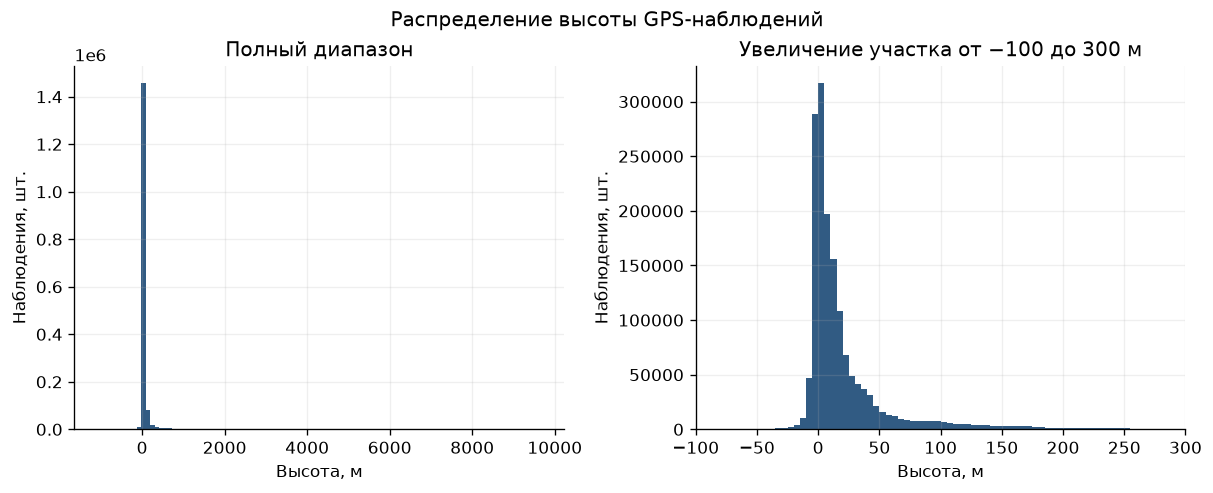

In [3]:
fig = plot_histogram(df, ROOT / 'plots')
plt.show()
plt.close(fig)

Медиана высоты — 7 м, среднее — 29.66 м; распределение имеет длинный правый хвост. За пределами увеличенного участка 33,801 значений.

## Рисунок 2 Высота по видам

Ящики показывают квартильный диапазон и медиану, усы — крайние значения внутри 1,5 IQR своей группы. Совпадающие значения выбросов отображены одной точкой; это не удаление строк. Обе категории превышают 1%; объединено 0 категорий.

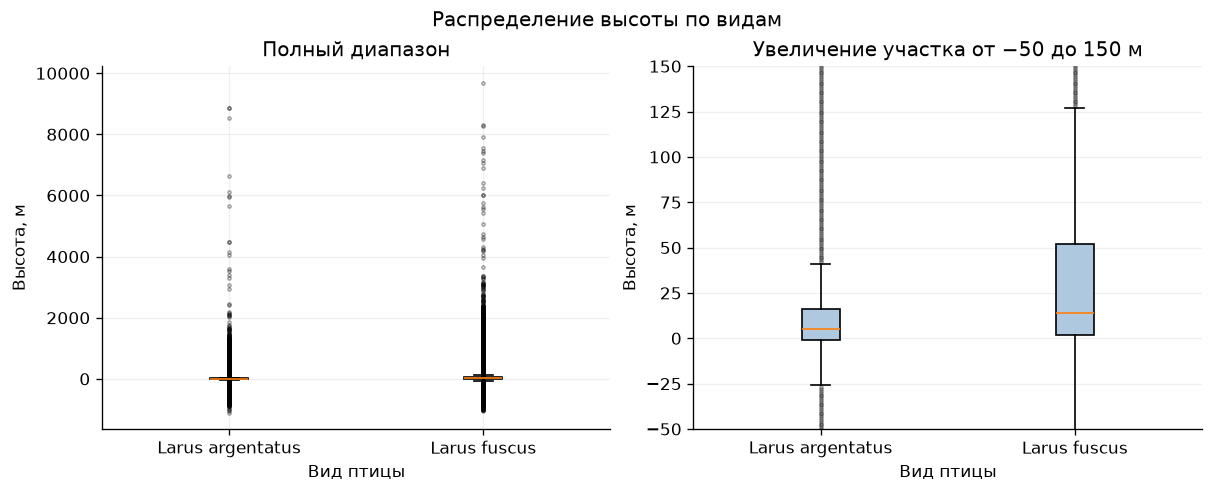

In [4]:
fig = plot_group_distribution(df, ROOT / 'plots')
plt.show()
plt.close(fig)

Медиана Larus argentatus — 5 м, Larus fuscus — 14 м. Разность 9 м описывает эти наблюдения, а не доказанное различие популяций.

## Таблица 2 Временные агрегаты

Выбран месяц: период наблюдений охватывает более трёх лет, дневной ряд был бы громоздким. Ниже полный календарь от первого до последнего месяца. `count` учитывает все строки; `valid` — непустые высоты. Для пустого месяца число строк равно нулю, медиана и среднее остаются NaN. Крайние месяцы неполные, поэтому прямое сравнение их объёмов с полными месяцами ограничено.

In [5]:
with pd.option_context('display.max_rows', None):
    display(monthly)

,count,valid,median_m,mean_m
period,,,,
2013-05,3346,3346,5.0,9.159594
2013-06,49500,49500,9.0,28.573697
2013-07,30004,30004,14.0,36.567358
2013-08,10875,10875,19.0,52.873839
2013-09,6956,6956,33.0,66.064692
2013-10,6978,6978,15.0,47.843938
2013-11,5254,5254,9.0,56.050247
2013-12,5394,5394,10.0,77.839451
2014-01,5322,5322,11.0,89.111612


## Рисунок 3 Временной ряд

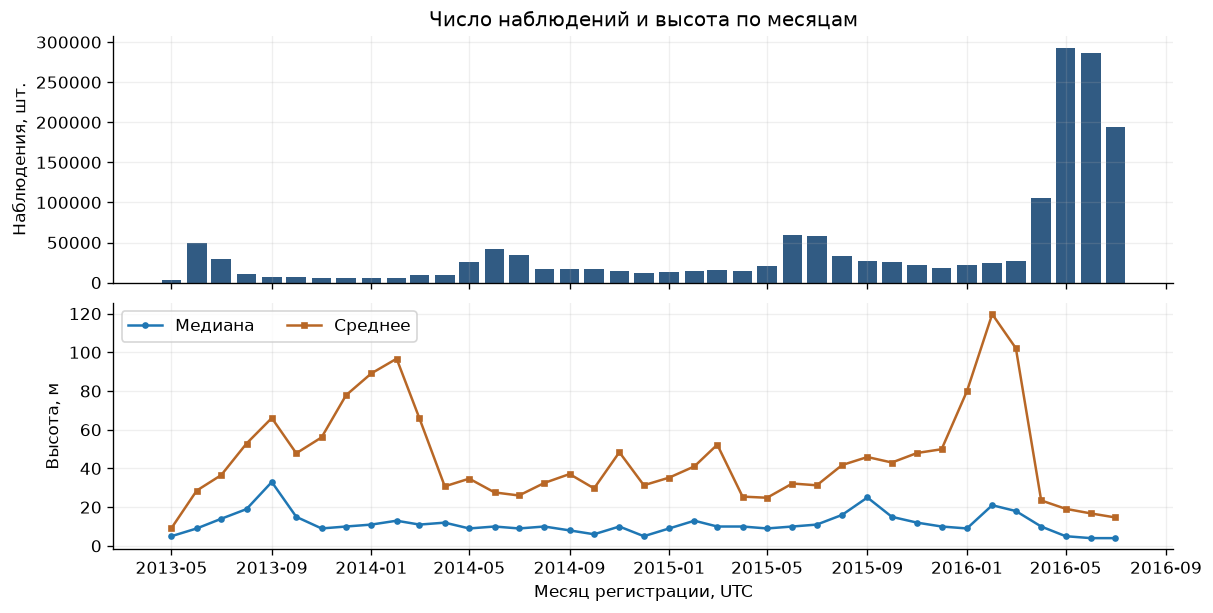

In [6]:
fig = plot_time(monthly, ROOT / 'plots')
plt.show()
plt.close(fig)

Наибольшее число наблюдений приходится на 2016-05: 292,741; календарь содержит 39 месяцев, пустых — 0.

## Таблица 3 Групповые агрегаты

Все исходные категории сохранены. `missing_fraction` и `share` представлены долями от 0 до 1.

In [7]:
display(groups)

,count,valid,median_m,mean_m,missing,missing_fraction,share
scientific_name,,,,,,,
Larus argentatus,1034332,1034321,5.0,15.566451,11,0.000011,0.646458
Larus fuscus,565668,565668,14.0,55.440142,0,0.000000,0.353542


## Рисунок 4 Число наблюдений по видам

Порог объединения редких групп — строго менее 1% от всех строк. В этом наборе объединено 0 категорий.

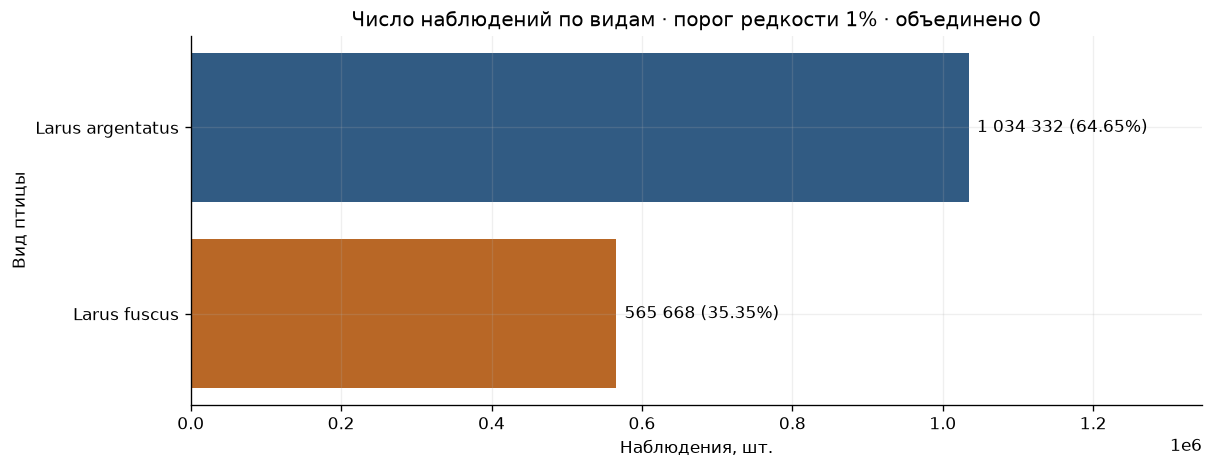

In [8]:
fig = plot_group_counts(df, ROOT / 'plots')
plt.show()
plt.close(fig)

Larus argentatus составляет 64.65% наблюдений; порог 1% не объединяет ни одну из двух категорий.

## Полная сводная таблица Вид на месяц

В ячейке медиана высоты в метрах. Отсутствующие сочетания остаются NaN, не заменяются нулями.

In [9]:
with pd.option_context('display.max_columns', None):
    display(pivot)

period,2013-05,2013-06,2013-07,2013-08,2013-09,2013-10,2013-11,2013-12,2014-01,2014-02,2014-03,2014-04,2014-05,2014-06,2014-07,2014-08,2014-09,2014-10,2014-11,2014-12,2015-01,2015-02,2015-03,2015-04,2015-05,2015-06,2015-07,2015-08,2015-09,2015-10,2015-11,2015-12,2016-01,2016-02,2016-03,2016-04,2016-05,2016-06,2016-07
scientific_name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Larus argentatus,4.0,4.0,0.0,2.0,0.0,0.0,1.0,6.0,5.0,8.0,10.0,13.0,9.0,9.0,9.0,4.0,0.0,0.0,3.5,0.0,7.0,11.0,10.0,12.0,11.0,7.0,7.0,8.0,10.0,7.0,8.0,9.0,6.0,16.0,19.0,10.0,5.0,2.0,2.0
Larus fuscus,7.0,10.0,18.0,26.0,67.0,28.0,15.0,12.0,13.0,18.0,13.0,9.0,8.0,10.0,9.0,25.0,59.0,38.0,20.0,9.0,11.5,16.0,10.0,7.0,7.0,16.0,29.0,73.0,82.0,40.0,17.0,10.0,12.0,35.0,17.0,9.0,5.0,12.0,14.0


## Рисунок 5 Тепловая карта сводной таблицы

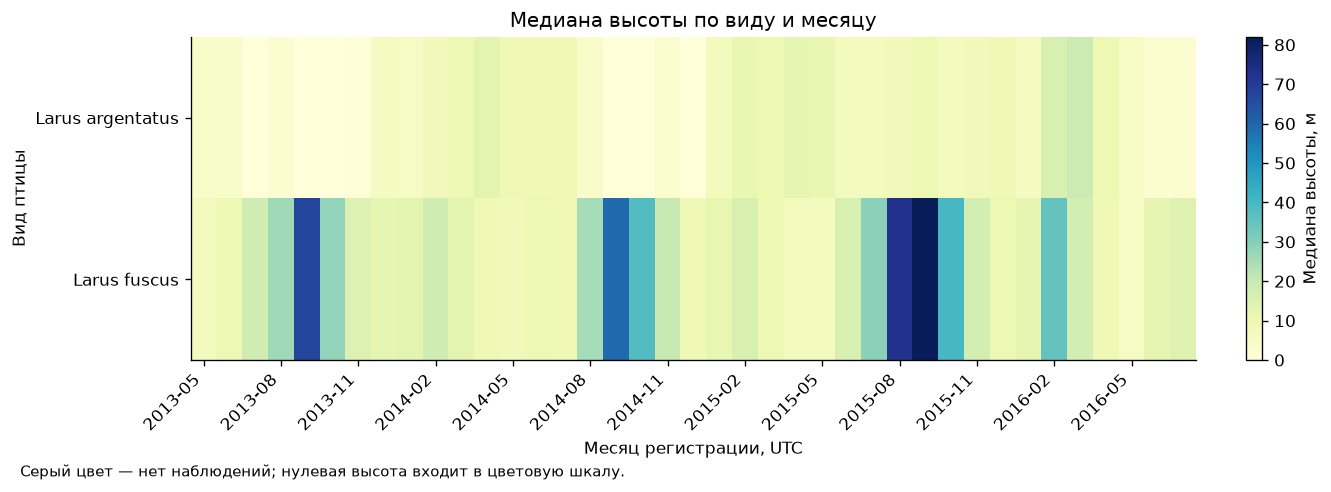

In [10]:
fig = plot_heatmap(pivot, ROOT / 'plots')
plt.show()
plt.close(fig)

Максимальная месячная медиана — 82 м у Larus fuscus в 2015-09. Сводная таблица содержит 2 вида × 39 месяцев; пустых сочетаний — 0.

## Таблица 4 Два правила аномалий

Знаменатель доли — все 1 600 000 строк. Столбец `overlap` показывает одно и то же пересечение для обоих правил; суммировать его по строкам нельзя. Маски рассчитаны заново, их длина совпадает с числом строк. Флаги IQR и отрицательной высоты точно совпали с ЛР1. Решение ЛР1 сохранить строки подтверждено; MAD из ЛР1 не является вторым правилом данной работы.

In [11]:
display(anomalies)
print('Длины масок:', {name: len(mask) for name, mask in masks.items()})

,rule,count,fraction,overlap
0,1.5 IQR,186965,0.116853,9646
1,Высота < 0 м,363699,0.227312,9646


Длины масок: {'iqr': 1600000, 'negative': 1600000}


## Рисунок 6 Отмеченные аномалии

Точки — уникальные значения высоты, вертикальная координата — их полная частота. Представлены все непустые значения, без подвыборки. Пунктир — границы IQR, точечная линия — 0 м.

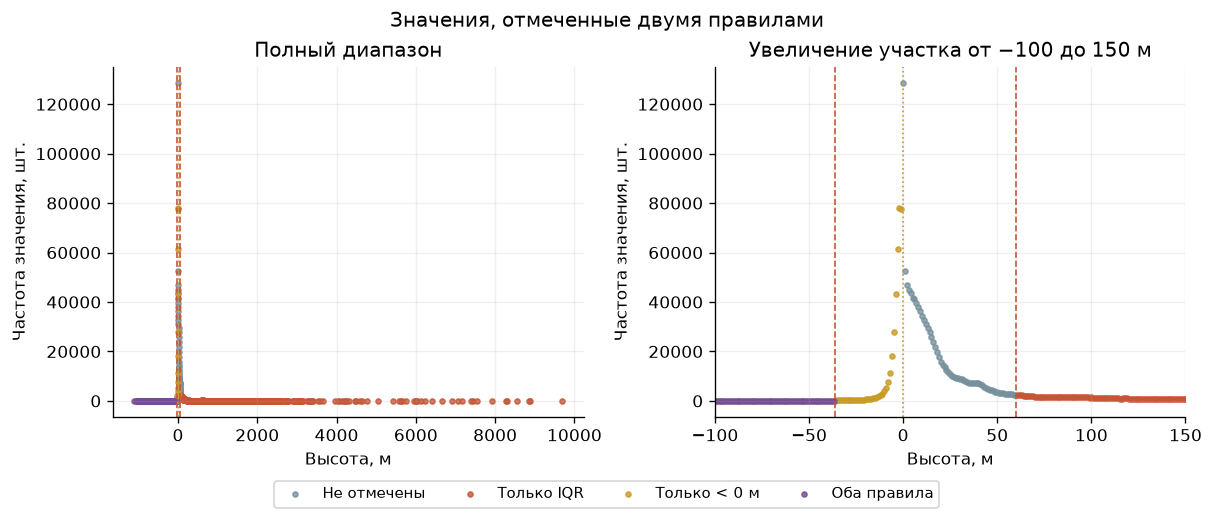

In [12]:
fig = plot_anomalies(df, masks, bounds, ROOT / 'plots')
plt.show()
plt.close(fig)

IQR отмечает 186,965 строк за границами [-36; 60] м; отрицательная высота встречается в 363,699 строках. Пересечение — 9,646 строк.

## Таблица 5 Цикл Python и NumPy

Метрика — средняя высота на одном float64-массиве из всех непустых значений. Перед замером результаты проверены `np.isclose(rtol=1e-12, atol=1e-12)`. По одному прогреву не учитывается; выполнено три повтора, сравниваются медианы времени. Загрузка данных и удаление пропусков из входного массива исключены из времени обеих реализаций. Сам файл не изменяется.

In [13]:
display(pd.DataFrame([{'Метод': 'Цикл Python', 'N': timing['n'], 'Среднее, м': timing['python_value'], 'Медиана времени, с': timing['python_seconds']},
                      {'Метод': 'NumPy', 'N': timing['n'], 'Среднее, м': timing['numpy_value'], 'Медиана времени, с': timing['numpy_seconds']}]))
print('Ускорение:', round(timing['speedup'], 2))
print('Повторы, с:', timing['samples_seconds'])
print('Версии:', timing['versions'])
print('Среда:', timing['platform'], timing['processor'])

,Метод,N,"Среднее, м","Медиана времени, с"
0,Цикл Python,1599989,29.663592,0.136881
1,NumPy,1599989,29.663592,0.001789


Ускорение: 76.51
Повторы, с: {'python': [0.14731559999927413, 0.13651840000238735, 0.1368813000008231], 'numpy': [0.0017891000024974346, 0.001909699996758718, 0.0017365000021527521]}
Версии: {'Python': '3.12.14', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'Matplotlib': '3.11.2', 'PyArrow': '26.0.0'}
Среда: Windows-10-10.0.19045-SP0 AMD64 Family 23 Model 8 Stepping 2, AuthenticAMD


Ускорение относится к этой машине, этому массиву и этим трём повторам. Оно не является универсальной оценкой производительности NumPy.

## Таблица 6 Соответствие графиков и выводов

In [14]:
display(pd.DataFrame({'Рисунок': range(1, 7),
    'Тип': ['Гистограмма', 'Ящики с усами', 'Временной ряд', 'Столбцы', 'Тепловая карта', 'Частоты с отметками'],
    'Оси': ['Высота, м / число', 'Вид / высота, м', 'Месяц UTC / число и высота, м', 'Число / вид', 'Месяц UTC / вид; цвет: медиана, м', 'Высота, м / частота'],
    'Наблюдение': conclusions}))

,Рисунок,Тип,Оси,Наблюдение
0,1,Гистограмма,"Высота, м / число","Медиана высоты — 7 м, среднее — 29.66 м; распр..."
1,2,Ящики с усами,"Вид / высота, м","Медиана Larus argentatus — 5 м, Larus fuscus —..."
2,3,Временной ряд,"Месяц UTC / число и высота, м",Наибольшее число наблюдений приходится на 2016...
3,4,Столбцы,Число / вид,Larus argentatus составляет 64.65% наблюдений;...
4,5,Тепловая карта,"Месяц UTC / вид; цвет: медиана, м",Максимальная месячная медиана — 82 м у Larus f...
5,6,Частоты с отметками,"Высота, м / частота","IQR отмечает 186,965 строк за границами [-36; ..."


## Итог и переход к ЛР3

У Larus fuscus медиана высоты 14 м, у Larus argentatus — 5 м; распределение асимметрично, поэтому одной средней недостаточно. В ЛР3 следует проверить устойчивость различия с учётом месяца и повторных измерений одних и тех же птиц. 1,6 млн строк относятся к 145 особям и не являются 1,6 млн независимых птиц. Здесь не выполнялись тесты гипотез, корреляционный анализ, бутстреп или логарифмическое преобразование.

В ЛР3 передаются неизменные поля `minimum_distance_above_surface_in_meters`, `event_date`, `scientific_name` и идентификатор особи `organism_id`. Обе маски аномалий используются как признаки качества и повод предметной проверки, без автоматического исключения строк.